In [5]:
!pip install -q scikit-learn seaborn tensorflow

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid")

In [7]:
bunch = load_breast_cancer()

X = pd.DataFrame(bunch.data, columns=bunch.feature_names)
y = pd.Series((bunch.target == 0).astype(int), name="malignant")

df = X.copy()
df["malignant"] = y

print("shape:", df.shape)
print("classes:", {0: "benign", 1: "malignant"})
display(df.head())
display(df.describe().T.round(3))

shape: (569, 31)
classes: {0: 'benign', 1: 'malignant'}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


,class,count
0,benign (0),357
1,malignant (1),212


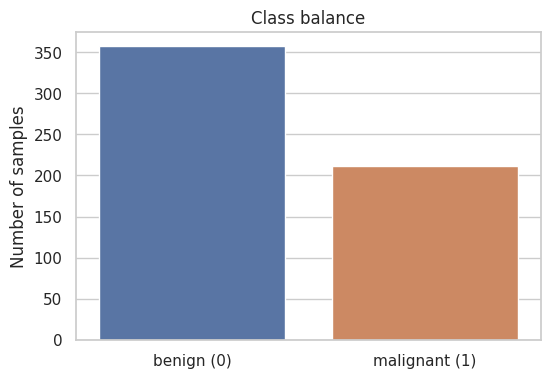

In [8]:
counts = y.value_counts().sort_index()
count_df = pd.DataFrame({
    "class": ["benign (0)", "malignant (1)"],
    "count": counts.values,
})
display(count_df)

plt.figure(figsize=(6, 4))
sns.barplot(data=count_df, x="class", y="count", hue="class", legend=False)
plt.title("Class balance")
plt.ylabel("Number of samples")
plt.xlabel("")
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

split_df = pd.DataFrame({
    "set": ["train", "test"],
    "samples": [len(y_train), len(y_test)],
    "malignant": [int(y_train.sum()), int(y_test.sum())],
    "benign": [int((y_train == 0).sum()), int((y_test == 0).sum())],
})
display(split_df)

,set,samples,malignant,benign
0,train,455,170,285
1,test,114,42,72


In [10]:
classical_models = {
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(kernel="rbf", C=1.0, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}

predictions = {}
for name, model in classical_models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(f"trained: {name}")

trained: Naive Bayes
trained: KNN
trained: Decision Tree
trained: Random Forest
trained: SVM
trained: Logistic Regression


In [11]:
ann = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])

ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

ann.summary()

history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=80,
    batch_size=16,
    verbose=0,
)

ann_proba = ann.predict(X_test_scaled, verbose=0).ravel()
predictions["ANN"] = (ann_proba >= 0.5).astype(int)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

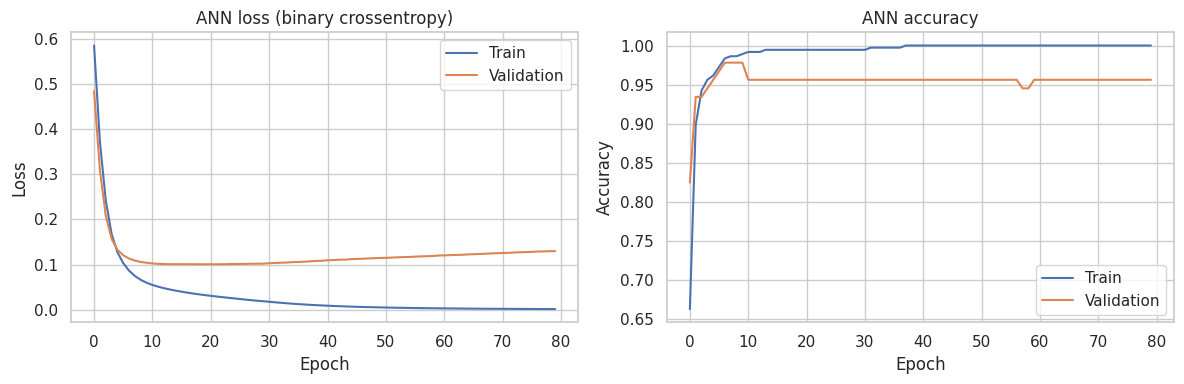

In [12]:
hist = pd.DataFrame(history.history)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="Train")
plt.plot(hist["val_loss"], label="Validation")
plt.title("ANN loss (binary crossentropy)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["accuracy"], label="Train")
plt.plot(hist["val_accuracy"], label="Validation")
plt.title("ANN accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
rows = []
cms = {}

for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    })
    cms[name] = confusion_matrix(y_test, y_pred)

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

for name, y_pred in predictions.items():
    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["benign", "malignant"],
        zero_division=0,
    ))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Naive Bayes,0.9211,0.9231,0.8571,0.8889
KNN,0.9561,0.9744,0.9048,0.9383
Decision Tree,0.9211,0.9459,0.8333,0.8861
Random Forest,0.9649,1.0000,0.9048,0.9500
SVM,0.9737,1.0000,0.9286,0.9630
Logistic Regression,0.9649,0.9750,0.9286,0.9512
ANN,0.9912,1.0000,0.9762,0.9880



 Naive Bayes
              precision    recall  f1-score   support

      benign       0.92      0.96      0.94        72
   malignant       0.92      0.86      0.89        42

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114


 KNN
              precision    recall  f1-score   support

      benign       0.95      0.99      0.97        72
   malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


 Decision Tree
              precision    recall  f1-score   support

      benign       0.91      0.97      0.94        72
   malignant       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92     

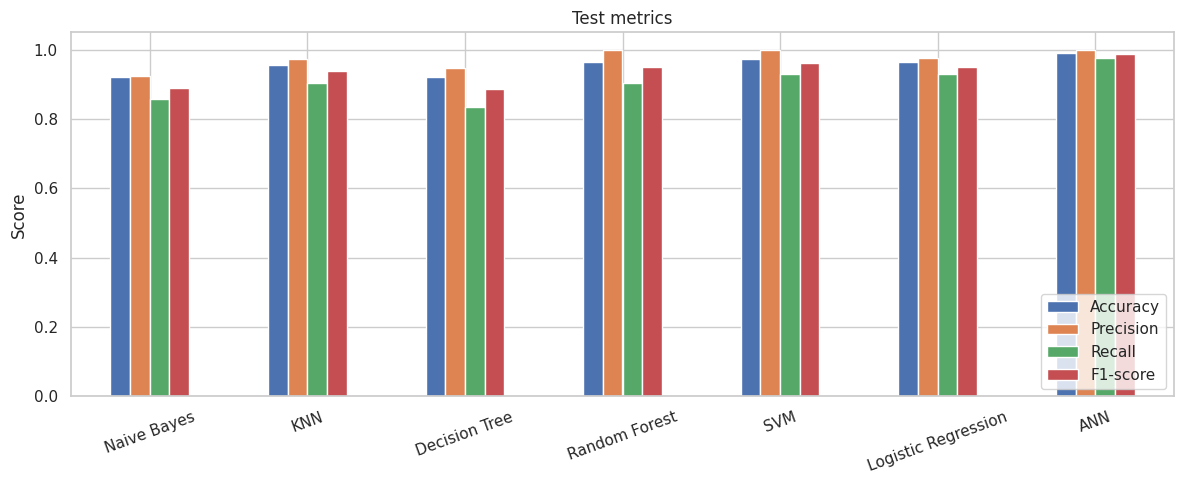

In [14]:
ax = results.plot(kind="bar", figsize=(12, 5), rot=20)
ax.set_title("Test metrics")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

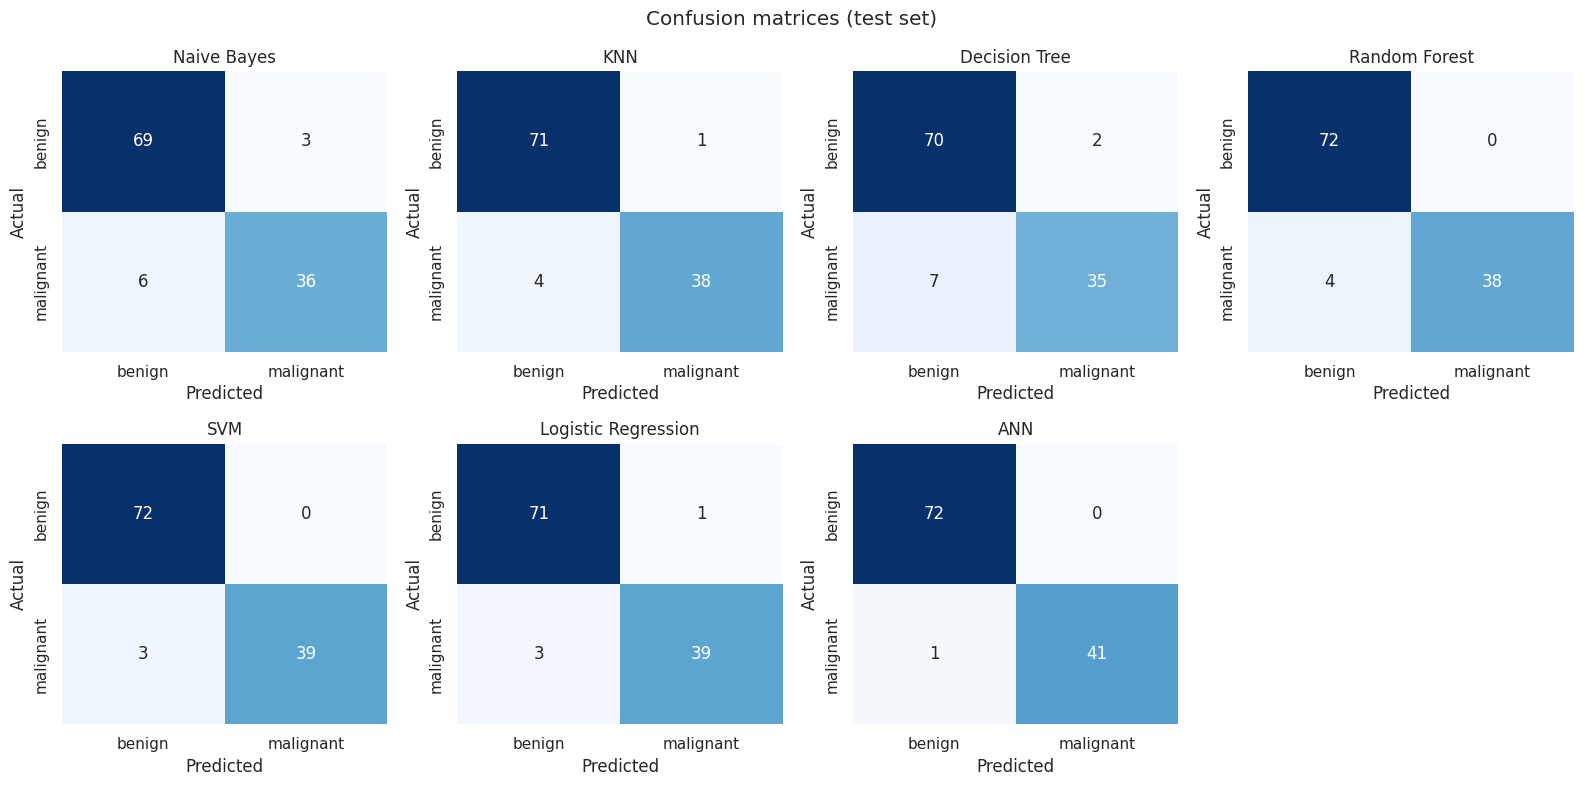

In [15]:
labels = ["benign", "malignant"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[-1].axis("off")
plt.suptitle("Confusion matrices (test set)")
plt.tight_layout()
plt.show()

In [16]:
best = results["F1-score"].idxmax()
print(best)
display(results.loc[[best]].round(4))

ANN


,Accuracy,Precision,Recall,F1-score
Model,,,,
ANN,0.9912,1.0,0.9762,0.988
